# BiLSTM-CRF POS for Burmese language

## Pipeline

1. Read raw dataset
2. Parse sentences into words and POS tags
3. Split train corpus into train/validation
4. Build vocabularies
5. Encode sentences
6. Create Dataset and DataLoader
7. Build BiLSTM-CRF
8. Train the model
9. Evaluate the model
10. Predict POS tags for new sentences

Dataset format example: \
ကျွန်တော်/pron စာ/n ဖတ်/v သည်/ppm ။/punc

Dataset link: https://github.com/ye-kyaw-thu/myPOS/blob/master/corpus-ver-3.0/corpus/mypos-ver.3.0.shuf.nopipe.txt \
(EDIT: I didn't notice there was an open test corpus file. So, I trying evaluating the model with test file at the last index.)

- Should try hyper-parameter tuning
- I tried building the model with sklearn-crfsuite and the accuracy was 96%
- This BiLSTM-CRF model's score is 98.56% but the computation power is the tradeoff

This notebook applies a **BiLSTM-CRF** architecture to Burmese POS tagging. The BiLSTM reads each sentence in both directions, while the CRF layer considers the tag sequence when producing the final predictions.

The goal is to compare this neural approach with the two earlier models: the feature-based CRF and the probability-based HMM. We'll consider both predictive performance and computational cost, since a higher score is only one part of choosing a model.

## Loading libraries

In [1]:
import os
import random
from pathlib import Path
from tqdm.auto import tqdm

from collections import Counter

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

import torch
import torch.nn as nn
from torchcrf import CRF
import torch.optim as optim
from torch.utils.data import (
    Dataset,
    DataLoader,
)
from torch.nn.utils.rnn import (
    pad_sequence,
    pack_padded_sequence,
    pad_packed_sequence,
)

import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

c:\Users\onest\miniconda3\envs\pytorch\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## GPU setup if available

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

Device : cuda


## Configuration

In [59]:
class Config:

    # Dataset
    ROOT = Path.cwd().parent
    DATA_DIR = ROOT / "dataset"
    TRAIN_DIR = DATA_DIR / "mypos-ver.3.0.shuf.nopipe.txt"
    TEST_DIR = DATA_DIR / "otest.1k.nopipe.txt"

    # Vocabulary
    MIN_FREQ = 1
    PAD_TOKEN = "<PAD>"
    UNK_TOKEN = "<UNK>"

    # Model
    EMBEDDING_DIM = 200
    HIDDEN_DIM = 128
    NUM_LAYERS = 2
    DROPOUT = 0.5

    # Training
    BATCH_SIZE = 32
    LEARNING_RATE = 0.001
    WEIGHT_DECAY = 1e-4
    EPOCHS = 10
    CLIP = 5.0

    # Others
    RANDOM_SEED = 42
    SAVE_DIR = ROOT / "models"

config = Config()

## Set random seeds

In [4]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(config.RANDOM_SEED)

print(f"Random seed set to {config.RANDOM_SEED}")

Random seed set to 42


## Read the corpus

In [5]:
def load_corpus(path):
    """Read a myPOS file into sentences of (word, tag) pairs.

    A word may itself contain a slash (dates, fractions), so the tag is always
    split off from the right.
    """
    sentences, invalid_lines = [], []
    with open(path, encoding="utf-8") as corpus:
        for lineno, line in enumerate(corpus, start=1):
            sentence = []
            for token in line.split():
                word, sep, tag = token.rpartition("/")
                if not sep or not word:
                    invalid_lines.append(f"Line {lineno}: Invalid token {token!r}")
                    continue
                sentence.append((word, tag))
            if sentence:
                sentences.append(sentence)
    return sentences, invalid_lines


train_sentences, train_invalid_lines = load_corpus(config.TRAIN_DIR)
test_sentences, test_invalid_lines = load_corpus(config.TEST_DIR)

In [6]:
train_sentences[0]

[('၁၉၆၂', 'num'),
 ('ခုနှစ်', 'n'),
 ('ခန့်မှန်း', 'v'),
 ('သန်းခေါင်စာရင်း', 'n'),
 ('အရ', 'ppm'),
 ('လူဦးရေ', 'n'),
 ('၁၁၅၉၃၁', 'num'),
 ('ယောက်', 'part'),
 ('ရှိ', 'v'),
 ('သည်', 'ppm'),
 ('။', 'punc')]

### Dataset stats

In [7]:
print(f"{'Train corpus':<12}: {len(train_sentences):,} sentences, "
      f"{sum(len(s) for s in train_sentences):,} tokens, {len(train_invalid_lines)} parsing problems")

print(f"{'Test file':<12}: {len(test_sentences):,} sentences, "
      f"{sum(len(s) for s in test_sentences):,} tokens, {len(test_invalid_lines)} parsing problems")

print(f"{'Tags':<12}:",
      ", ".join(sorted({t for s in train_sentences for _, t in s})))

Train corpus: 43,196 sentences, 564,517 tokens, 0 parsing problems
Test file   : 1,000 sentences, 13,468 tokens, 0 parsing problems
Tags        : abb, adj, adv, conj, fw, int, n, num, part, ppm, pron, punc, sb, tn, v


The training corpus contains **43,196 sentences and 564,517 tokens**, while the separate test corpus contains **1,000 sentences and 13,468 tokens**. Both files have zero parsing problems, and the dataset uses the same 15 POS labels as the previous notebooks.

## Parsing the sentences into word and tag

In [8]:
def parse_corpus(sentence):
    """
    convert the corpus into words and tags lists
    """
    words = []
    tags = []

    for w, t in sentence:
        words.append(w)
        tags.append(t)

    return words, tags

## Testing the parser

In [9]:
words, tags = parse_corpus(train_sentences[0])

print(words)
print()
print(tags)

['၁၉၆၂', 'ခုနှစ်', 'ခန့်မှန်း', 'သန်းခေါင်စာရင်း', 'အရ', 'လူဦးရေ', '၁၁၅၉၃၁', 'ယောက်', 'ရှိ', 'သည်', '။']

['num', 'n', 'v', 'n', 'ppm', 'n', 'num', 'part', 'v', 'ppm', 'punc']


## Parsing the entire corpus

In [10]:
corpus_words = []
corpus_labels = []
test_words = []
test_labels = []

for sentence in train_sentences:
    words, tags = parse_corpus(sentence)
    if len(words) == 0:
        continue

    corpus_words.append(words)
    corpus_labels.append(tags)

print("Parsed train sentences :", len(corpus_words))


for sentence in test_sentences:
    words, tags = parse_corpus(sentence)
    if len(words) == 0:
        continue

    test_words.append(words)
    test_labels.append(tags)
print("Parsed train sentences :", len(test_words))

Parsed train sentences : 43196
Parsed train sentences : 1000


The corpus is split into training and validation portions using an 80/20 sentence-level split. The separate 1,000-sentence test file is retained for final evaluation, which is a more reliable model-development setup than choosing hyperparameters directly on the test set.

The fixed random seed also helps make the split and training process more reproducible.

## Splitting the train corpus into train(80%) and val(20%)

In [15]:
train_words, val_words, train_labels, val_labels = train_test_split(
    corpus_words,
    corpus_labels,
    test_size=(0.2),
    random_state=config.RANDOM_SEED,
    shuffle=True
)

The vocabulary is built from the training portion only. The `<UNK>` token provides a fallback for words not observed in the training vocabulary, while `<PAD>` is used to make variable-length sentences fit into batches.

The final vocabulary contains **22,001 entries**, and the tag vocabulary contains **15 POS labels**, matching the earlier CRF and HMM experiments.

## Building the word vocabulary

In [16]:
word_counter = Counter()

for word in train_words:
    word_counter.update(word)

print("Unique words :", len(word_counter))

Unique words : 21999


In [17]:
word2idx = {
    config.PAD_TOKEN: 0,
    config.UNK_TOKEN: 1
}

for word, freq in word_counter.items():

    if freq >= config.MIN_FREQ:
        word2idx[word] = len(word2idx)

idx2word = {
    idx: word for word, idx in word2idx.items()
}

print("Vocabulary size :", len(word2idx))

Vocabulary size : 22001


The word counter finds **21,999 unique words** in the training split, and the final vocabulary contains **22,001 entries** after adding `<PAD>` and `<UNK>`. Since `MIN_FREQ=1`, every word observed in the training split is retained.

Words that appear only in validation or test data are mapped to `<UNK>`, which is the intended behavior for unseen vocabulary items.

## Building the tag vocab

In [18]:
tag_counter = Counter()

for tags in train_labels:
    tag_counter.update(tags)

print(tag_counter)

Counter({'part': 108565, 'n': 98665, 'ppm': 69461, 'v': 67469, 'punc': 43326, 'pron': 16392, 'conj': 14334, 'adj': 13138, 'adv': 8544, 'num': 4768, 'tn': 4672, 'fw': 2630, 'int': 535, 'abb': 291, 'sb': 214})


In [19]:
tag2idx = {}

for tag in sorted(tag_counter.keys()):
    tag2idx[tag] = len(tag2idx)

idx2tag = {
    idx: tag for tag, idx in tag2idx.items()
}

print(tag2idx)

{'abb': 0, 'adj': 1, 'adv': 2, 'conj': 3, 'fw': 4, 'int': 5, 'n': 6, 'num': 7, 'part': 8, 'ppm': 9, 'pron': 10, 'punc': 11, 'sb': 12, 'tn': 13, 'v': 14}


## Vocab statistics

In [20]:
print("="*50)
print("Vocabulary Statistics")
print("="*50)
print(f"Word Vocabulary : {len(word2idx)}")
print(f"Tag Vocabulary  : {len(tag2idx)}")
print(f"PAD index       : {word2idx[config.PAD_TOKEN]}")
print(f"UNK index       : {word2idx[config.UNK_TOKEN]}")

Vocabulary Statistics
Word Vocabulary : 22001
Tag Vocabulary  : 15
PAD index       : 0
UNK index       : 1


## Sentence encoder

In [21]:
def encode_words(sentence, word2idx):
    """
    Convert words to integer IDs.
    Unknown words become UNK.
    """
    return [
        word2idx.get(word, word2idx[config.UNK_TOKEN])
        for word in sentence
    ]

def encode_tags(tags, tag2idx):
    """
    Convert POS tags to integer IDs.
    """
    return [
        tag2idx[tag]
        for tag in tags
    ]

## Encoding step

In [22]:
train_inputs = [
    encode_words(s, word2idx)
    for s in train_words
]


train_outputs = [
    encode_tags(t, tag2idx)
    for t in train_labels
]

test_inputs = [
    encode_words(s, word2idx)
    for s in test_words
]


test_outputs = [
    encode_tags(t, tag2idx)
    for t in test_labels
]

val_inputs = [
    encode_words(s, word2idx)
    for s in val_words
]


val_outputs = [
    encode_tags(t, tag2idx)
    for t in val_labels
]

In [23]:
train_inputs[0]

[2, 3, 4, 5]

## Creating POSDataset

In [24]:
class POSDataset(Dataset):
    """
    tensors for pos tagging
    """

    def __init__(self, inputs, labels):
        """
        Parameters
        ----------
        inputs : List[List[int]]
            Encoded word IDs.

        labels : List[List[int]]
            Encoded tag IDs.
        """

        self.inputs = inputs
        self.labels = labels

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, idx):
        return (
            torch.tensor(self.inputs[idx], dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.long)
        )

In [32]:
train_dataset = POSDataset(train_inputs, train_outputs)
print("Training samples:", len(train_dataset))

Training samples: 34556


## Printing one sample of train dataset

In [33]:
words, tags = train_dataset[0]

print("Word IDs")
print(words)

print()

print("Tag IDs")
print(tags)

Word IDs
tensor([2, 3, 4, 5])

Tag IDs
tensor([ 6, 14,  9, 11])


## Padding stage

In [34]:
def collate_fn(batch):
    """
    pads sequences in a batch.

    returns
    -------
    padded_inputs
    padded_labels
    lengths
    mask
    """

    inputs = [item[0] for item in batch]
    labels = [item[1] for item in batch]

    # original sequence lengths
    lengths = torch.tensor(
        [len(seq) for seq in inputs],
        dtype=torch.long
    )

    # pad input sequences
    padded_inputs = pad_sequence(
        inputs,
        batch_first=True,
        padding_value=word2idx[config.PAD_TOKEN]
    )

    # pad label sequences
    padded_labels = pad_sequence(
        labels,
        batch_first=True,
        padding_value=0
    )

    # Mask: True for real tokens, False for padding
    mask = padded_inputs != word2idx[config.PAD_TOKEN]

    return (
        padded_inputs,
        padded_labels,
        lengths,
        mask
    )

## Testing the collate function

In [35]:
sample_batch = [
    train_dataset[0],
    train_dataset[1],
    train_dataset[2]
]

inputs, labels, lengths, mask = collate_fn(sample_batch)
print("Inputs Shape :", inputs.shape)
print("Labels Shape :", labels.shape)
print("Lengths Shape:", lengths.shape)
print("Mask Shape   :", mask.shape)
print()
print(inputs)
print()
print(mask)

Inputs Shape : torch.Size([3, 22])
Labels Shape : torch.Size([3, 22])
Lengths Shape: torch.Size([3])
Mask Shape   : torch.Size([3, 22])

tensor([[ 2,  3,  4,  5,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
          0,  0,  0,  0],
        [ 6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23,
         24, 25, 26,  5],
        [27, 28, 29, 30,  5,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
          0,  0,  0,  0]])

tensor([[ True,  True,  True,  True, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, False],
        [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
          True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
          True,  True],
        [ True,  True,  True,  True,  True, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False, False,
         False, Fa

The sample batch confirms that variable-length sentences are padded to a common length and accompanied by a mask. Shorter sentences receive padding at the end, while the mask marks which positions contain real tokens.

This is important because padding positions should not contribute to the sequence loss or decoding.

## Create the dataset objects

In [36]:
train_dataset = POSDataset(
    train_inputs,
    train_outputs
)

val_dataset = POSDataset(
    val_inputs,
    val_outputs
)

test_dataset = POSDataset(
    test_inputs,
    test_outputs
)

## Create the data loaders

In [37]:
train_loader = DataLoader(
    train_dataset,
    batch_size=config.BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=config.BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=config.BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

In [38]:
batch = next(iter(train_loader))
inputs, labels, lengths, mask = batch

print(inputs.shape)
print(labels.shape)
print(lengths.shape)
print(mask.shape)

torch.Size([32, 45])
torch.Size([32, 45])
torch.Size([32])
torch.Size([32, 45])


With a batch size of **32**, this batch is padded to a maximum sequence length of 45. The input and label tensors have matching shapes, while the length and mask tensors provide the information needed to handle variable-length sentences correctly.

The architecture combines a 200-dimensional word embedding, a two-layer bidirectional LSTM with 128 hidden units per direction, dropout at 0.5, a linear layer, and a CRF decoder over the 15 POS tags.

Compared with the earlier feature-based CRF, this model learns its word representations and contextual patterns from data rather than relying only on manually designed neighboring-word features. The CRF layer then helps produce a coherent sequence of tags.

## Building the model

In [39]:
class BiLSTMCRF(nn.Module):

    def __init__(
        self,
        vocab_size,
        tagset_size,
        embedding_dim,
        hidden_dim,
        num_layers,
        dropout,
        pad_idx,
    ):

        super().__init__()

        # embedding layer
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=pad_idx,
        )

        # bi-lstm layer
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0,
        )

        # dropout layer
        self.dropout = nn.Dropout(dropout)

        # linear layer
        self.fc = nn.Linear(
            hidden_dim * 2,
            tagset_size,
        )

        # crf layer
        self.crf = CRF(
            tagset_size,
            batch_first=True,
        )

        self._initialize_weights()

    def _initialize_weights(self):
        for name, param in self.named_parameters():
            if "weight" in name and param.dim() > 1:
                nn.init.xavier_uniform_(param)
            elif "bias" in name:
                nn.init.zeros_(param)

    def forward(self,input_ids,tags,mask):
        embeddings = self.embedding(input_ids)
        lstm_out, _ = self.lstm(embeddings)
        lstm_out = self.dropout(lstm_out)
        emissions = self.fc(lstm_out)
        loss = -self.crf(
            emissions,
            tags,
            mask=mask,
            reduction="mean",
        )
        return loss

    def decode(self,input_ids,mask):
        embeddings = self.embedding(input_ids)
        lstm_out, _ = self.lstm(embeddings)
        lstm_out = self.dropout(lstm_out)
        emissions = self.fc(lstm_out)
        prediction = self.crf.decode(
            emissions,
            mask=mask,
        )
        return prediction
        

In [40]:
model = BiLSTMCRF(
    vocab_size=len(word2idx),
    tagset_size=len(tag2idx),
    embedding_dim=config.EMBEDDING_DIM,
    hidden_dim=config.HIDDEN_DIM,
    num_layers=config.NUM_LAYERS,
    dropout=config.DROPOUT,
    pad_idx=word2idx[config.PAD_TOKEN],
)
model = model.to(device)
print(model)

BiLSTMCRF(
  (embedding): Embedding(22001, 200, padding_idx=0)
  (lstm): LSTM(200, 128, num_layers=2, batch_first=True, dropout=0.5, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=256, out_features=15, bias=True)
  (crf): CRF(num_tags=15)
)


In [41]:
batch = next(iter(train_loader))

input_ids, tags, lengths, mask = batch

input_ids = input_ids.to(device)
tags = tags.to(device)
mask = mask.to(device)

loss = model(
    input_ids,
    tags,
    mask,
)

print(loss)

tensor(41.0149, device='cuda:0', grad_fn=<NegBackward0>)


AdamW is used for optimization, with weight decay as a regularization measure. The learning-rate scheduler reduces the learning rate when validation loss stops improving, while gradient clipping helps limit unusually large gradient updates.

These choices matter because recurrent neural networks are more computationally demanding and have more training dynamics to manage than the HMM or feature-based CRF.

## Setting up the citerion and learning rate schedular

In [42]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=config.LEARNING_RATE,
    weight_decay=config.WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
)

## Train function

In [43]:
def train_one_epoch(model, dataloader, optimizer, device):

    model.train()

    total_loss = 0.0

    progress_bar = tqdm(
        dataloader,
        desc="Training",
        leave=False
    )

    for input_ids, tags, lengths, mask in progress_bar:

        input_ids = input_ids.to(device)
        tags = tags.to(device)
        mask = mask.to(device)

        optimizer.zero_grad()

        loss = model(
            input_ids=input_ids,
            tags=tags,
            mask=mask
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        optimizer.step()

        total_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    return total_loss / len(dataloader)

## Validation function

In [44]:
def validate(model, dataloader, device):

    model.eval()

    total_loss = 0.0

    with torch.no_grad():

        progress_bar = tqdm(
            dataloader,
            desc="Validation",
            leave=False
        )

        for input_ids, tags, lengths, mask in progress_bar:

            input_ids = input_ids.to(device)
            tags = tags.to(device)
            mask = mask.to(device)

            loss = model(
                input_ids=input_ids,
                tags=tags,
                mask=mask
            )

            total_loss += loss.item()

    return total_loss / len(dataloader)

The model is trained for up to **10 epochs**, with both training and validation loss tracked after each epoch. Validation loss is especially important: training loss can keep falling even after the model starts to generalize less effectively to unseen sentences.

We'll use the loss history to check whether that happens in this run.

## Complete training

In [45]:
train_losses = []
val_losses = []

epoch_progress = tqdm(range(config.EPOCHS), desc="Epochs")

for epoch in epoch_progress:

    print(f"\nEpoch {epoch+1}/{config.EPOCHS}")

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        device,
    )

    val_loss = validate(
        model,
        val_loader,
        device,
    )

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    epoch_progress.set_postfix(
        train_loss=f"{train_loss:.4f}",
        val_loss=f"{val_loss:.4f}",
    )

    print(f"Train Loss : {train_loss:.4f}")
    print(f"Valid Loss : {val_loss:.4f}")

Epochs:   0%|          | 0/10 [00:00<?, ?it/s]


Epoch 1/10


Epochs:  10%|█         | 1/10 [00:58<08:48, 58.74s/it, train_loss=4.8807, val_loss=2.0938]

Train Loss : 4.8807
Valid Loss : 2.0938

Epoch 2/10


Epochs:  20%|██        | 2/10 [01:59<07:58, 59.82s/it, train_loss=1.7785, val_loss=1.9097]

Train Loss : 1.7785
Valid Loss : 1.9097

Epoch 3/10


... (12 outputs left out)

Epochs:  90%|█████████ | 9/10 [11:07<01:03, 63.02s/it, train_loss=0.5645, val_loss=2.3724]

Train Loss : 0.5645
Valid Loss : 2.3724

Epoch 10/10


Epochs: 100%|██████████| 10/10 [12:04<00:00, 72.44s/it, train_loss=0.5071, val_loss=2.4976]

Train Loss : 0.5071
Valid Loss : 2.4976


Training loss decreases steadily from **4.8807** in epoch 1 to **0.5071** in epoch 10. Validation loss behaves differently: it reaches its lowest recorded value of **1.8088 at epoch 4**, then rises to **2.4976 by epoch 10**.

This divergence is a clear sign that the model begins to overfit after epoch 4: it continues improving on the training data while validation loss gets worse. The notebook evaluates the final epoch rather than restoring the best validation checkpoint. Saving the checkpoint with the lowest validation loss or adding early stopping would be a useful next improvement.

## Plotting the loss curve

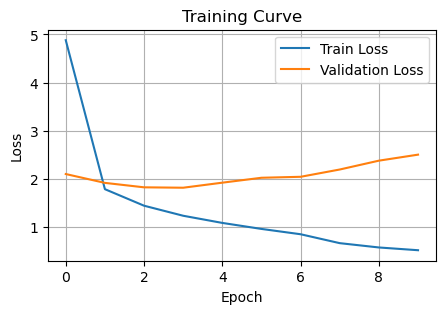

In [46]:
plt.figure(figsize=(5,3))

plt.plot(
    train_losses,
    label="Train Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Curve")
plt.legend()
plt.grid(True)
plt.show()

After training, the model decodes complete tag sequences for the test sentences. The evaluation compares predictions with the gold labels while using the mask to ignore padded positions.

This notebook does not report exact-sentence accuracy, unlike the earlier CRF and HMM notebooks. The token-level metrics are useful, but they do not tell us directly how many complete sentences were tagged perfectly.

## Prediction function

In [47]:
def predict(model, dataloader, device):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for input_ids, tags, lengths, mask in tqdm(dataloader):

            input_ids = input_ids.to(device)
            mask = mask.to(device)

            predictions = model.decode(
                input_ids=input_ids,
                mask=mask
            )

            tags = tags.cpu().numpy()
            mask = mask.cpu().numpy()

            for pred, gold, m in zip(predictions, tags, mask):

                length = m.sum()

                all_predictions.extend(pred[:length])
                all_labels.extend(gold[:length])

    return all_labels, all_predictions

In [48]:
true_labels, pred_labels = predict(
    model,
    test_loader,
    device
)

100%|██████████| 32/32 [00:00<00:00, 42.73it/s]


Token accuracy measures the share of individual words assigned the correct POS tag. The model reaches **98.56%**, meaning roughly 1.44% of the evaluated tokens are incorrect.

Accuracy alone can be dominated by frequent labels, so the macro-F1 score in the next section gives a more balanced view across all 15 POS categories.

## Token accuracy

In [49]:
accuracy = accuracy_score(
    true_labels,
    pred_labels
)

print(f"Token Accuracy: {accuracy:.4f}")

Token Accuracy: 0.9856


The model records **98.56% weighted F1** and **97.88% macro-F1**. Weighted F1 gives more influence to frequent labels, while macro-F1 gives each POS category equal weight.

The relatively small gap suggests that the overall result is not driven only by the most common labels. The per-tag report gives a closer look at where the model performs well and where the limited number of examples makes results less certain.

## precision/recall/f1

In [52]:
# Weighted metrics
p_weighted, r_weighted, f1_weighted, _ = (
    precision_recall_fscore_support(
        true_labels,
        pred_labels,
        average="weighted",
        zero_division=0
    )
)

# Macro metrics
p_macro, r_macro, f1_macro, _ = (
    precision_recall_fscore_support(
        true_labels,
        pred_labels,
        average="macro",
        zero_division=0
    )
)

print(f"Weighted Precision: {p_weighted:.4f}")
print(f"Weighted Recall   : {r_weighted:.4f}")
print(f"Weighted F1       : {f1_weighted:.4f}")
print(f"Macro Precision   : {p_macro:.4f}")
print(f"Macro Recall      : {r_macro:.4f}")
print(f"Macro F1          : {f1_macro:.4f}")

Weighted Precision: 0.9856
Weighted Recall   : 0.9856
Weighted F1       : 0.9856
Macro Precision   : 0.9809
Macro Recall      : 0.9768
Macro F1          : 0.9788


The report shows strong results for frequent tags, including `n` (F1 **0.9888**), `part` (**0.9892**), `ppm` (**0.9898**), `punc` (**1.0000**), and `v` (**0.9802**).

The smaller classes need more careful interpretation. For example, `sb` has only **3** test examples and `abb` has **12**, so perfect scores on these labels are encouraging but not enough to establish consistently strong performance. Among the better-supported classes, `adj` (F1 **0.9396**) and `adv` (**0.9419**) are comparatively more challenging, though both remain above 0.93.

## Classification report

In [53]:
tag_names = [
    idx2tag[i]
    for i in range(len(idx2tag))
]

print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=tag_names,
        digits=4,
    )
)

              precision    recall  f1-score   support

         abb     1.0000    1.0000    1.0000        12
         adj     0.9448    0.9344    0.9396       366
         adv     0.9567    0.9275    0.9419       262
        conj     0.9729    0.9611    0.9670       411
          fw     0.9762    0.9425    0.9591        87
         int     0.9600    0.9600    0.9600        25
           n     0.9913    0.9863    0.9888      3000
         num     1.0000    0.9935    0.9968       155
        part     0.9890    0.9893    0.9892      3189
         ppm     0.9893    0.9903    0.9898      2060
        pron     0.9812    0.9874    0.9843       476
        punc     1.0000    1.0000    1.0000      1270
          sb     1.0000    1.0000    1.0000         3
          tn     0.9792    0.9930    0.9860       142
           v     0.9735    0.9871    0.9802      2010

    accuracy                         0.9856     13468
   macro avg     0.9809    0.9768    0.9788     13468
weighted avg     0.9856   

The confusion matrix helps show which POS labels the model tends to mix up. This is useful because two models can have similar overall accuracy while making very different kinds of mistakes.

It is worth checking whether `v` and `part` remain a source of confusion. They were the most persistent error pair in the earlier HMM analysis and were also present among the remaining errors in the tuned feature-based CRF.

## Confusion matrix

In [54]:
cm = confusion_matrix(
    true_labels,
    pred_labels
)

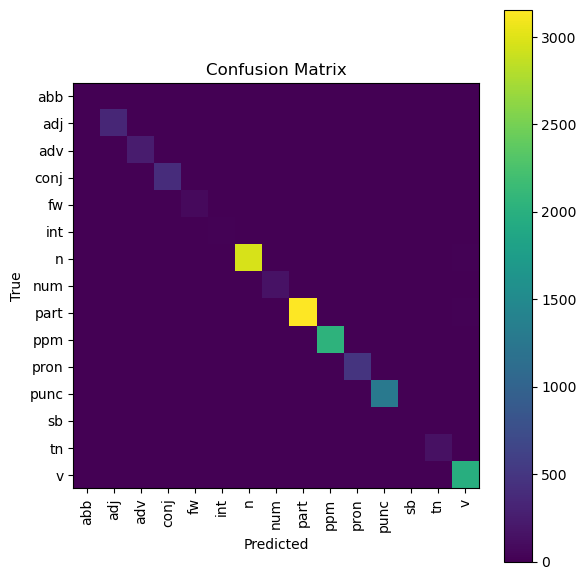

In [55]:
plt.figure(figsize=(6, 6))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")

plt.xticks(
    range(len(tag_names)),
    tag_names,
    rotation=90
)
plt.yticks(
    range(len(tag_names)),
    tag_names
)

plt.colorbar()
plt.tight_layout()
plt.show()

This example demonstrates the model's end-to-end use on a new sentence. The input is split on spaces, so it assumes the Burmese text has already been segmented into words.

That preprocessing requirement matters: predictions depend on token boundaries matching the style used during training. This is a useful demonstration, but not a complete raw-text processing pipeline.

## Predict new sentence

In [56]:
def predict_sentence(
    sentence,
    model,
    word2idx,
    idx2tag,
    device,
    unk_token="<UNK>",
):
    """
    Predict POS tags for a Space-separated sentence.
    returns list of (word, predicted_tag)
    """

    model.eval()
    tokens = sentence.strip().split()
    input_ids = [word2idx.get(word, word2idx[unk_token]) for word in tokens]
    input_ids = torch.tensor(
        [input_ids],
        dtype=torch.long,
        device=device
    )
    mask = torch.ones_like(
        input_ids,
        dtype=torch.bool
    )


    with torch.no_grad():
        prediction = model.decode(
            input_ids=input_ids,
            mask=mask
        )[0]

    predicted_tags = [
        idx2tag[idx]
        for idx in prediction
    ]

    return list(zip(tokens, predicted_tags))

In [57]:
sent1 = "မြန်မာစာ ကို ချစ် ပါ"
sent2 = "မြန်မာစာ ကို မြတ်နိုး ပါ"
sent3 = "သုတေသန များ ဆောင်ရွက် ပါ ။"

result = predict_sentence(
    sent3,
    model,
    word2idx,
    idx2tag,
    device,
)

for word, tag in result:
    print(f"{word:<20} {tag}")

သုတေသန               n
များ                 part
ဆောင်ရွက်            v
ပါ                   part
။                    punc


Saving the model weights allows the trained network to be restored later, provided the same model configuration and vocabularies are also available. For a reusable application, keep `word2idx`, `idx2tag`, and the configuration alongside the checkpoint.

## Saving the model

In [60]:
MODEL_PATH = config.SAVE_DIR / "bilstm_crf_pos_tagger.pth"
torch.save(model.state_dict(), MODEL_PATH)
print("Model saved successfully!")

Model saved successfully!


## Comparing the three POS-tagging approaches

The table below brings together the reported results from this BiLSTM-CRF notebook and the earlier HMM and feature-based CRF notebooks. All three use the same 1,000-sentence test corpus with 13,468 tokens and the same 15 POS labels.

| Model / reported setting | Token accuracy | Macro-F1 | Notes |
|---|---:|---:|---|
| HMM baseline | 94.94% | 90.07% | Fast training; probability-based sequence model |
| HMM tuned (`alpha=0.01`) | 95.37% | 91.43% | Modest gain after smoothing |
| Feature CRF baseline | 97.04% | 94.85% | Uses manually designed contextual features |
| Feature CRF tuned (`c1=0.0`, `c2=0.001`) | 99.67% | 99.76% | Highest reported score, but selected on the test set |
| **BiLSTM-CRF (this notebook)** | **98.56%** | **97.88%** | Learned contextual representations; 10-epoch run |

### What stands out?

- **The BiLSTM-CRF clearly outperforms the HMM** in this run: token accuracy is higher by **3.62 percentage points**, and macro-F1 by **6.45 points**, compared with the tuned HMM.
- **It also improves on the feature CRF baseline** by **1.52 points in token accuracy** and **3.03 points in macro-F1**. This suggests that learned word representations and bidirectional context are useful for this task.
- **The tuned feature CRF has the highest reported metrics**, exceeding this BiLSTM-CRF by **1.11 points in token accuracy** and **1.88 points in macro-F1**. But this is not a clean head-to-head win: its hyperparameters were selected using the same test set on which the score was reported. The BiLSTM-CRF uses a separate validation split for training monitoring, so its test result is the more defensible held-out comparison among these recorded experiments.
- **The HMM is the lightweight option.** Its earlier run trained in about 0.4 seconds, while this BiLSTM-CRF took about 12 minutes for 10 epochs. The neural model's performance gain therefore comes with a noticeably higher computational cost.

### Overall takeaway

The BiLSTM-CRF offers a strong balance between performance and evaluation discipline. It substantially improves on the HMM and beats the feature CRF baseline, while learning contextual representations directly from the training data. The tuned feature CRF's reported score is higher, but it should be re-evaluated with validation-based tuning before drawing a firm conclusion.

One more practical point: validation loss is lowest at epoch 4, while the reported test metrics come from epoch 10. Re-evaluating with the best-validation checkpoint could improve generalization and make the comparison even more informative.

# References

### Architecture inspiration
https://arxiv.org/abs/1603.01354 \
https://github.com/ZubinGou/NER-BiLSTM-CRF-PyTorch/tree/main

### Dataset
https://github.com/ye-kyaw-thu/myPOS/blob/master/corpus-ver-3.0/corpus/